In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240612_TS_C10_W20_11mM_run5.DSC", exp_type="francklab_esr/romana") # cooling 3 --initial sample
d2 = find_file("240612_TS_C10_W20_11mM_run6.DSC", exp_type="francklab_esr/romana") # heating 3 subsequently --after cooling and heating

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'cooling 3 (below transition)')

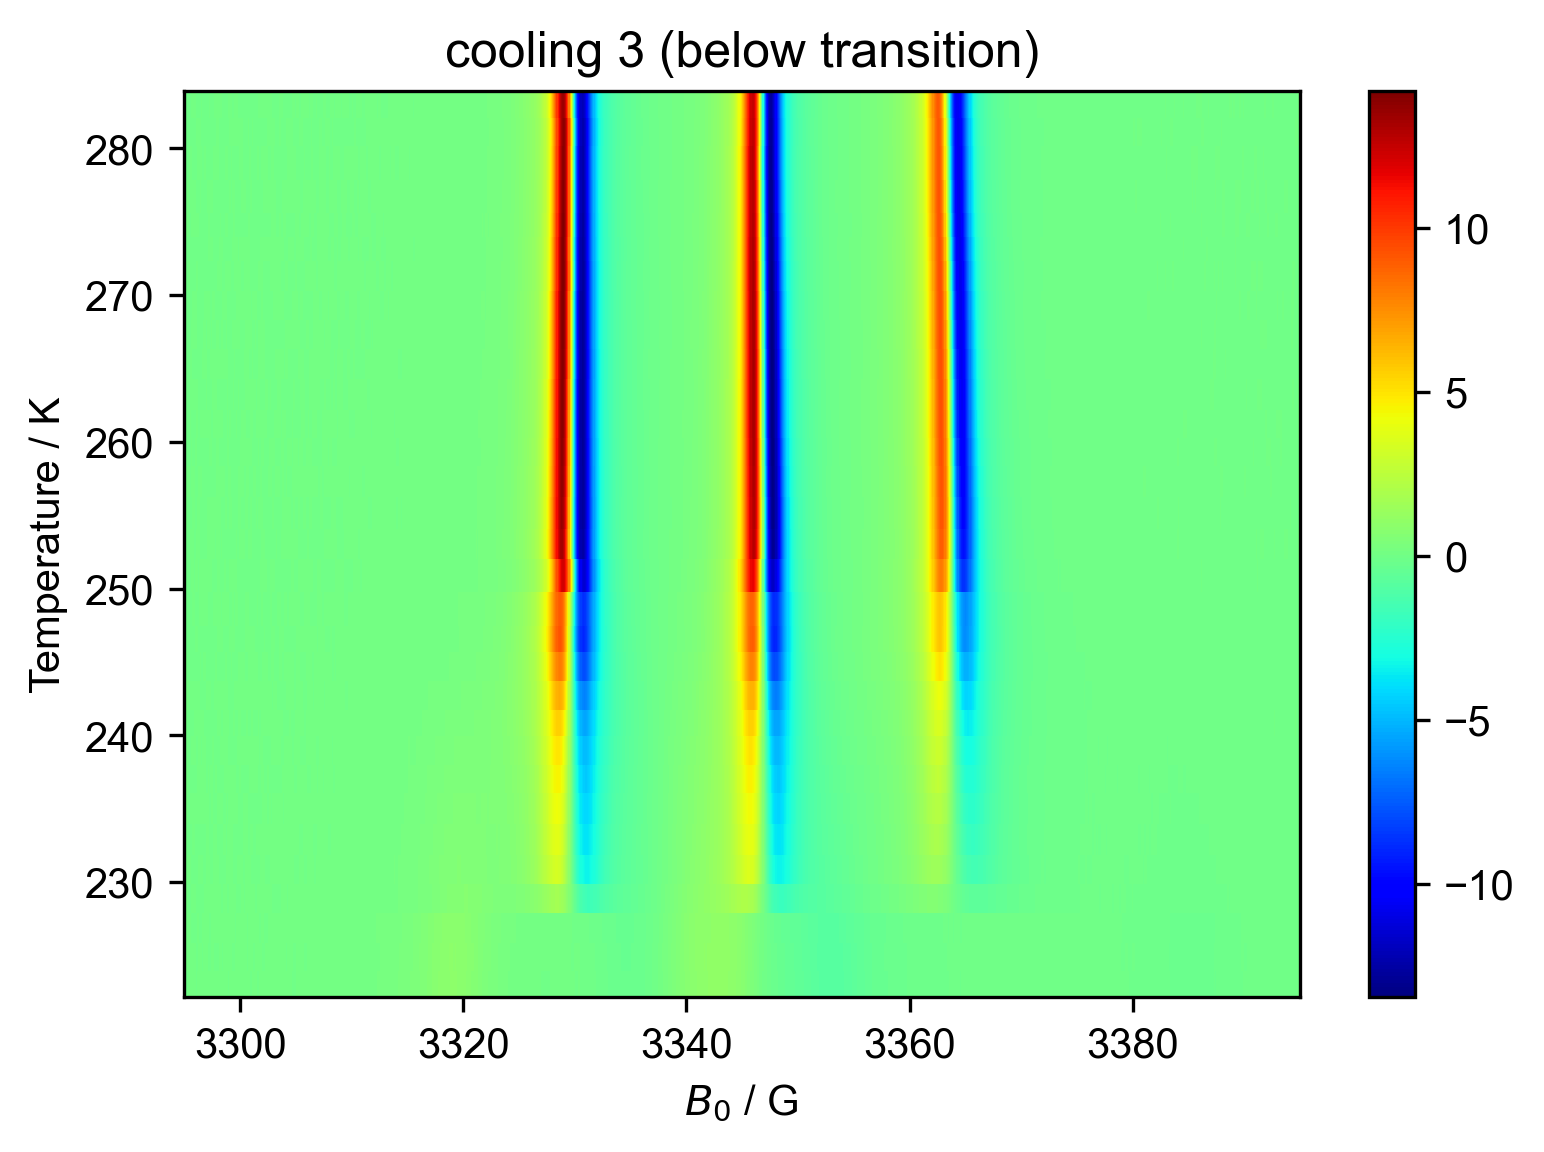

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("cooling 3 (below transition)")

Text(0.5, 1.0, 'heating 3 (below transition)')

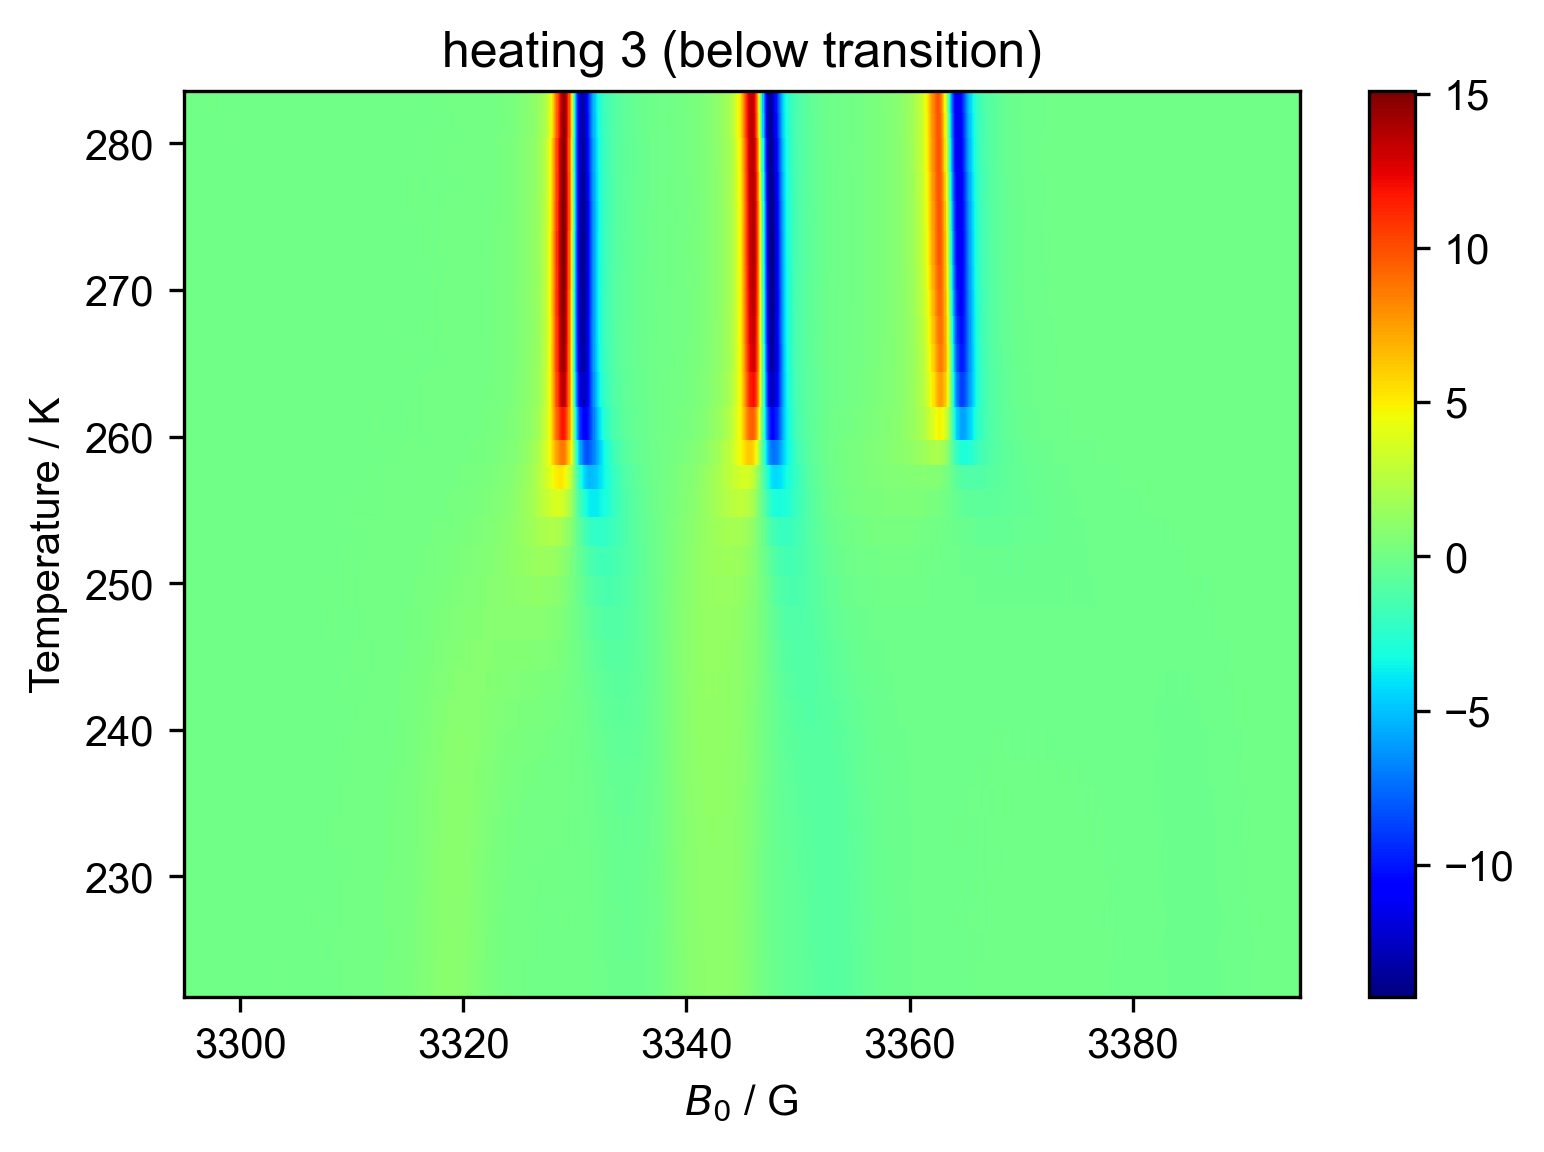

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("heating 3 (below transition)")

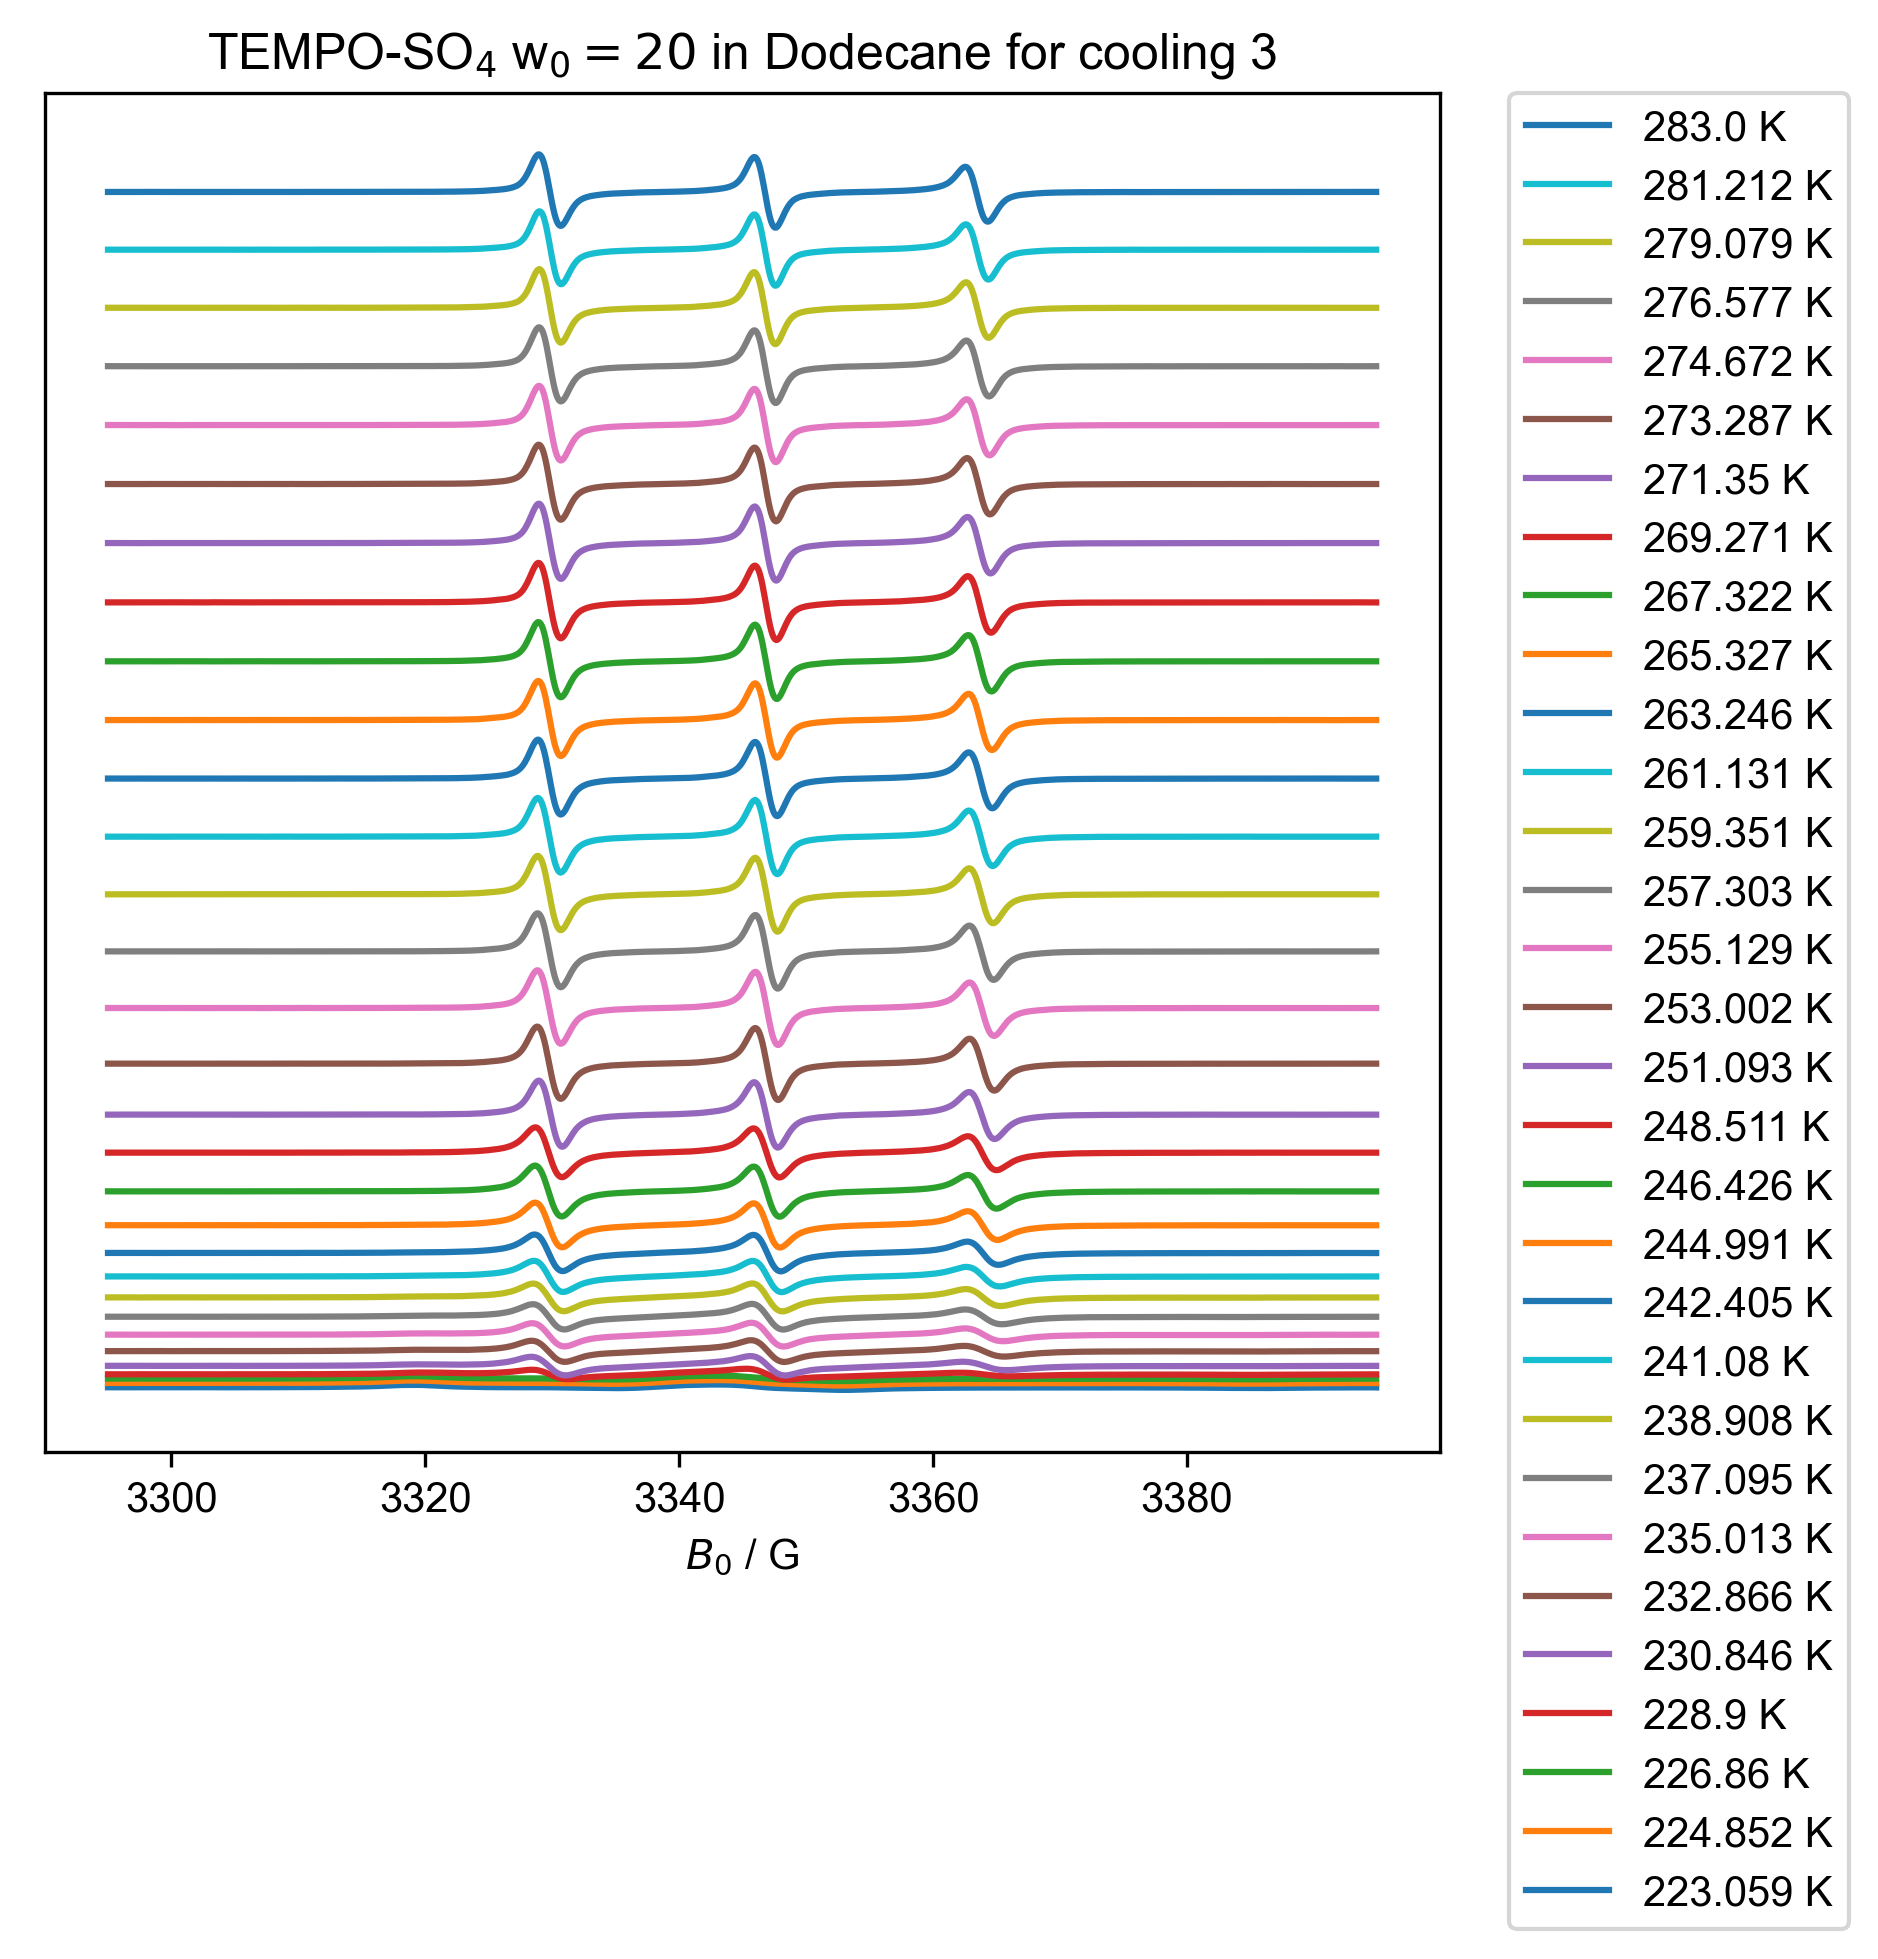

In [9]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 20$ in Dodecane for cooling 3", (200, 300))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

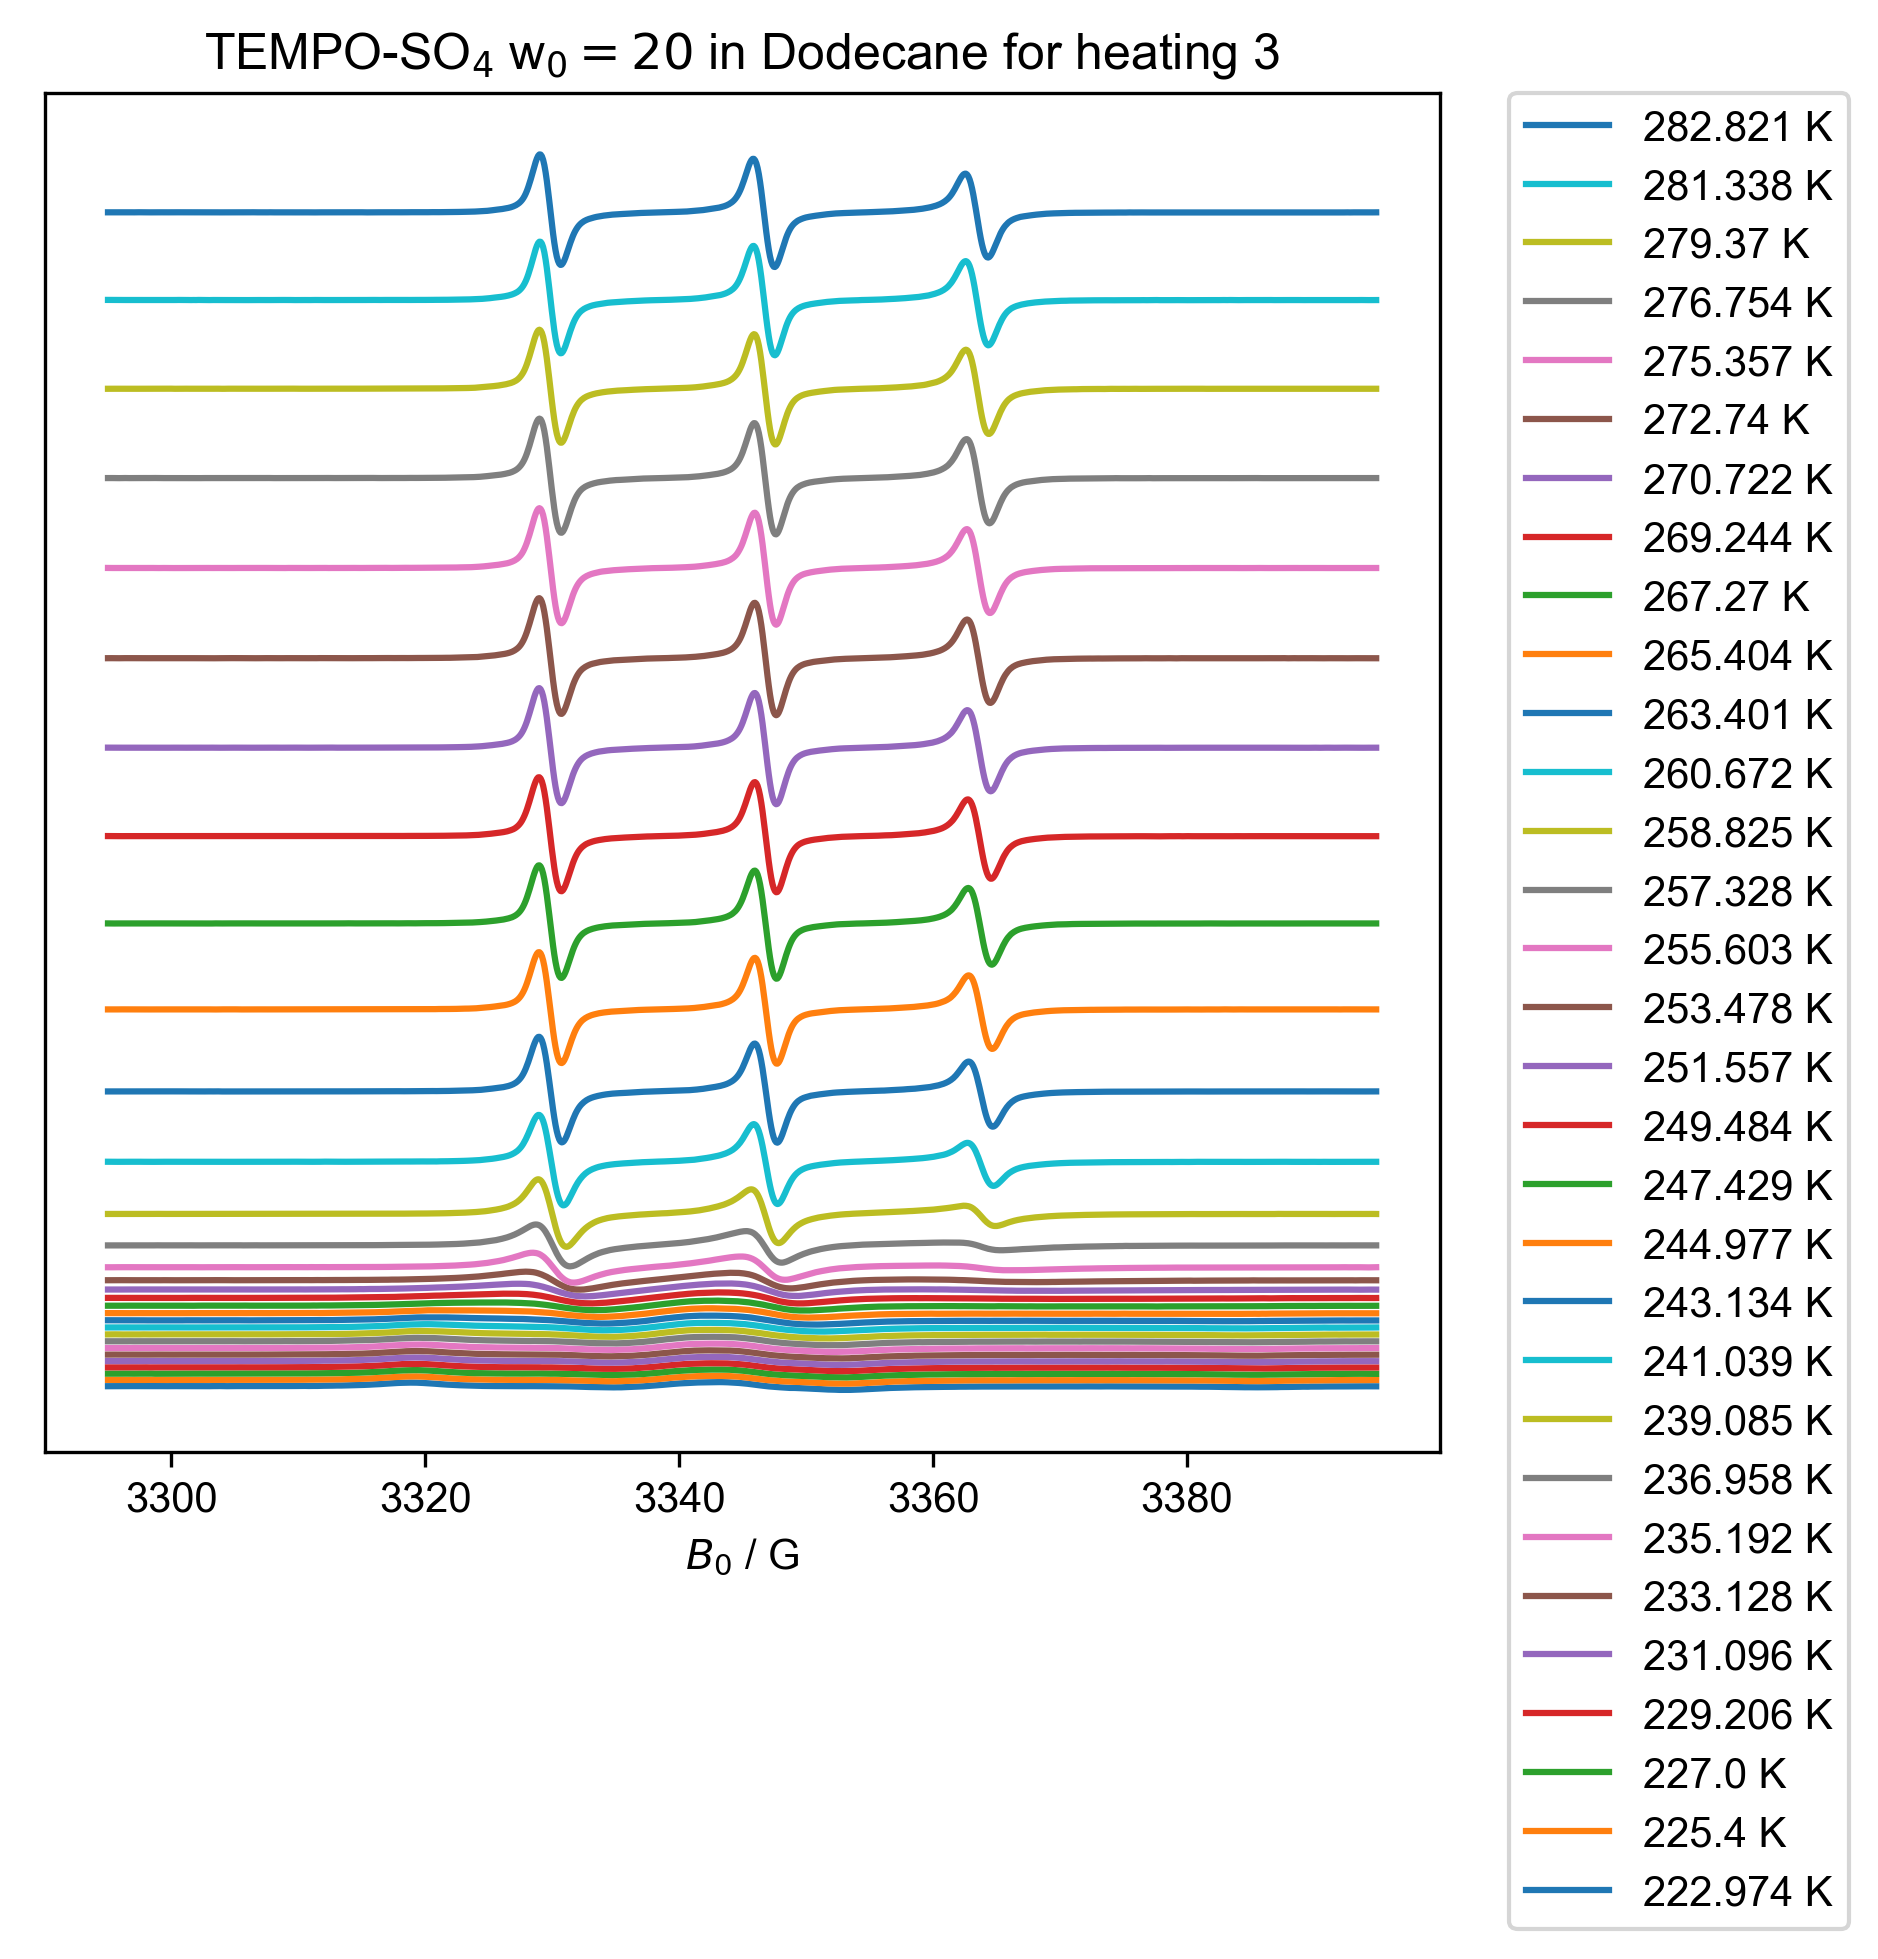

In [10]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0=20$ in Dodecane for heating 3", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[223.059 224.852 226.86  228.9   230.846 232.866 235.013 237.095 238.908
 241.08  242.405 244.991 246.426 248.511 251.093 253.002 255.129 257.303
 259.351 261.131 263.246 265.327 267.322 269.271 271.35  273.287 274.672
 276.577 279.079 281.212 283.   ]
[222.974 225.4   227.    229.206 231.096 233.128 235.192 236.958 239.085
 241.039 243.134 244.977 247.429 249.484 251.557 253.478 255.603 257.328
 258.825 260.672 263.401 265.404 267.27  269.244 270.722 272.74  275.357
 276.754 279.37  281.338 282.821]


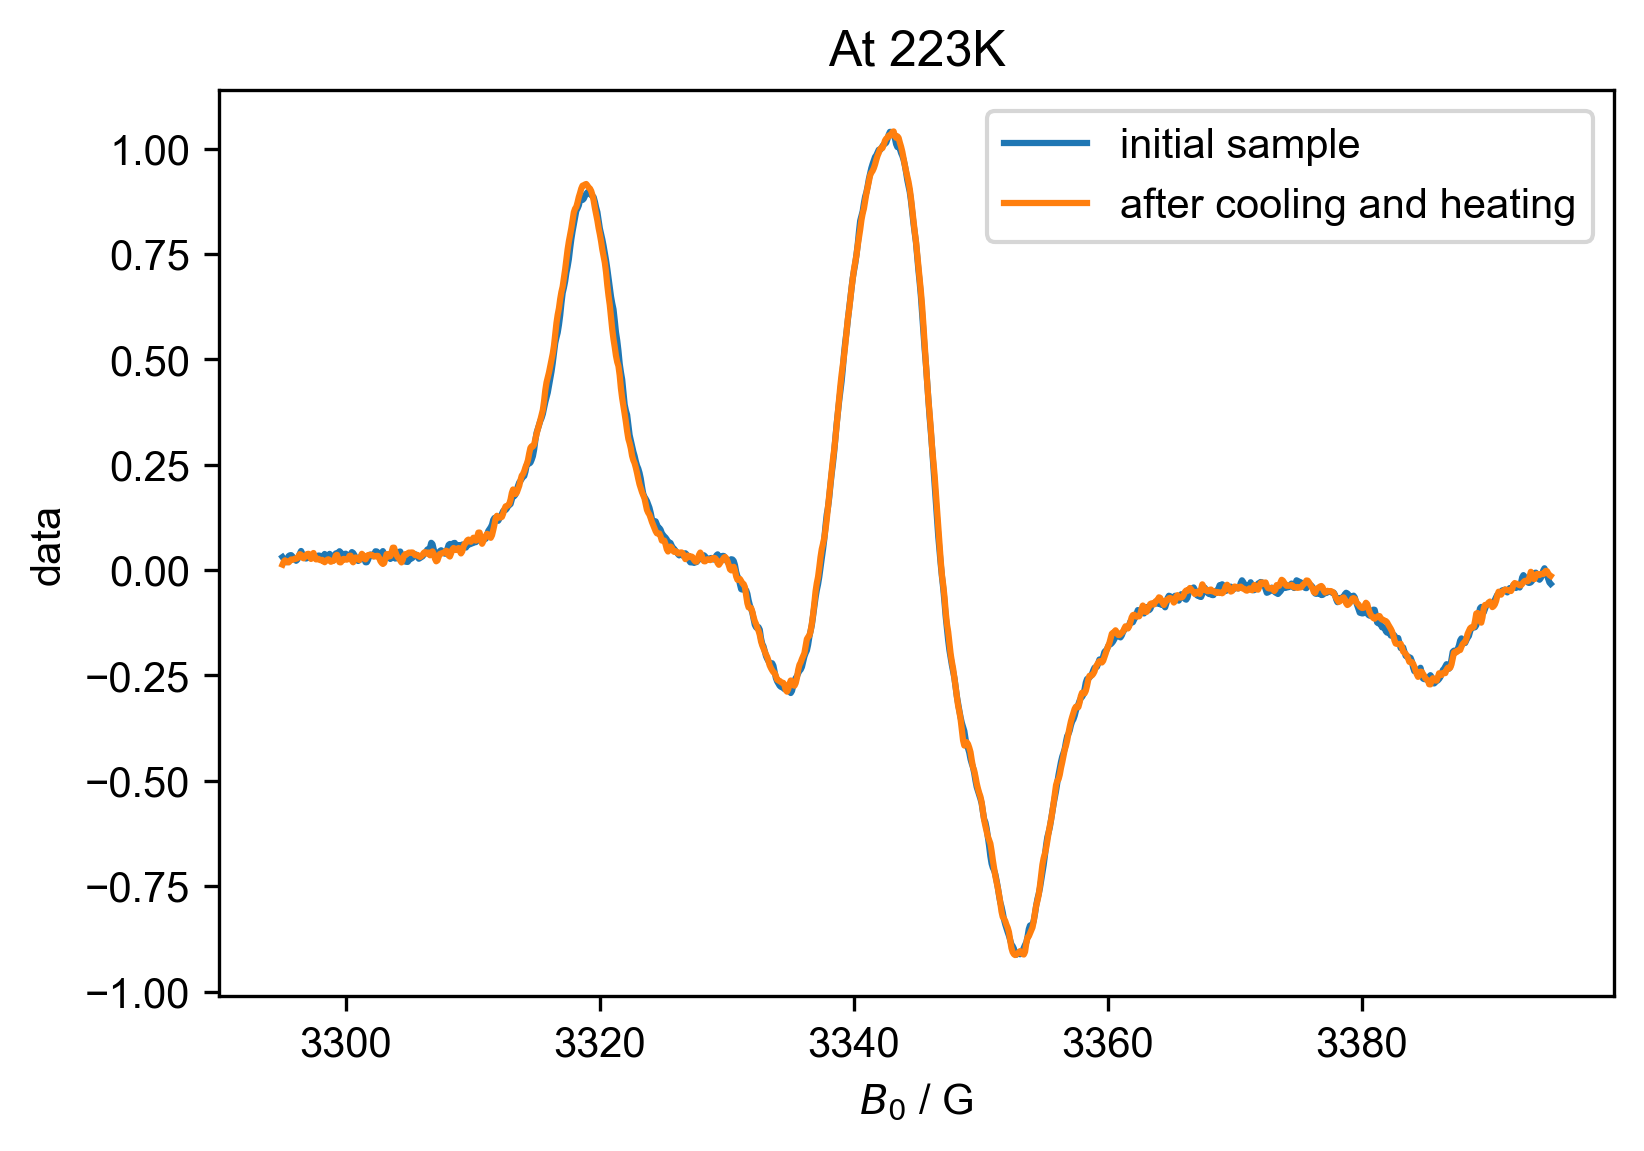

In [11]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":223], label="initial sample")
plot(d2["Temperature":223], label="after cooling and heating")
title("At 223K")
legend()

[223.059 224.852 226.86  228.9   230.846 232.866 235.013 237.095 238.908
 241.08  242.405 244.991 246.426 248.511 251.093 253.002 255.129 257.303
 259.351 261.131 263.246 265.327 267.322 269.271 271.35  273.287 274.672
 276.577 279.079 281.212 283.   ]
[222.974 225.4   227.    229.206 231.096 233.128 235.192 236.958 239.085
 241.039 243.134 244.977 247.429 249.484 251.557 253.478 255.603 257.328
 258.825 260.672 263.401 265.404 267.27  269.244 270.722 272.74  275.357
 276.754 279.37  281.338 282.821]


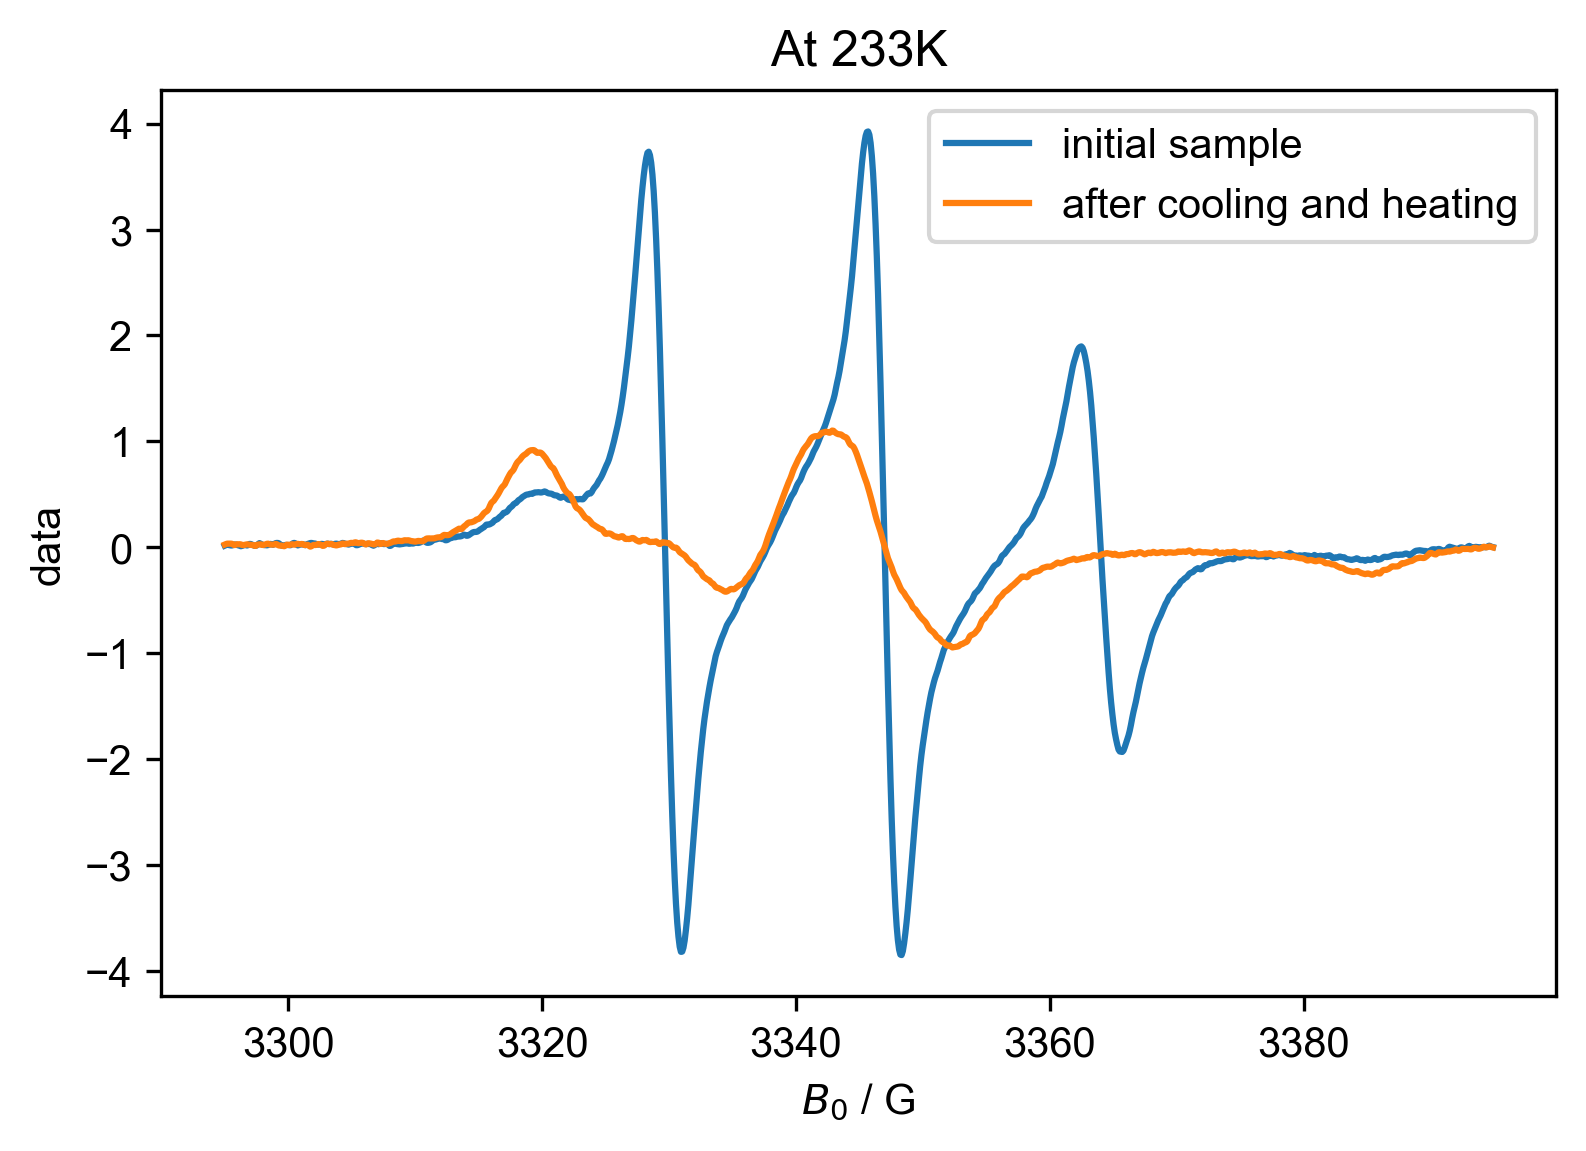

In [12]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":233], label="initial sample")
plot(d2["Temperature":233], label="after cooling and heating")
title("At 233K")
legend()

[223.059 224.852 226.86  228.9   230.846 232.866 235.013 237.095 238.908
 241.08  242.405 244.991 246.426 248.511 251.093 253.002 255.129 257.303
 259.351 261.131 263.246 265.327 267.322 269.271 271.35  273.287 274.672
 276.577 279.079 281.212 283.   ]
[222.974 225.4   227.    229.206 231.096 233.128 235.192 236.958 239.085
 241.039 243.134 244.977 247.429 249.484 251.557 253.478 255.603 257.328
 258.825 260.672 263.401 265.404 267.27  269.244 270.722 272.74  275.357
 276.754 279.37  281.338 282.821]


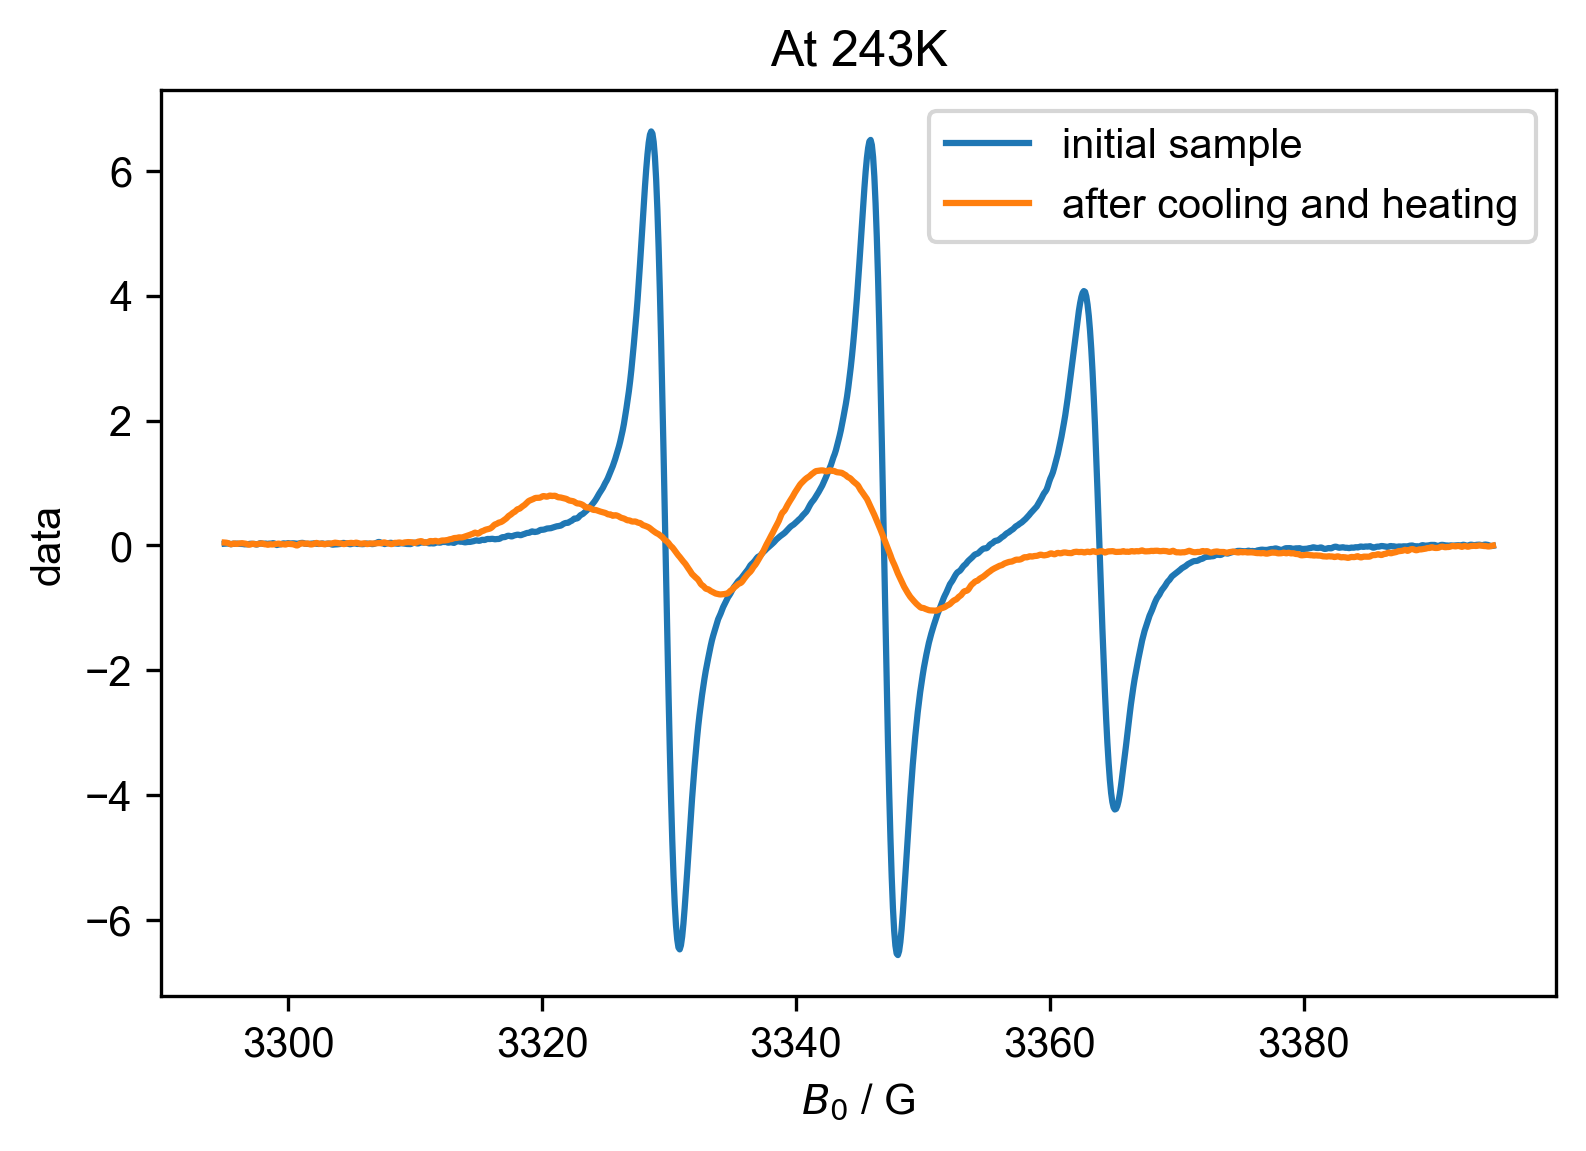

In [13]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":243], label="initial sample")
plot(d2["Temperature":243], label="after cooling and heating")
title("At 243K")
legend()

[223.059 224.852 226.86  228.9   230.846 232.866 235.013 237.095 238.908
 241.08  242.405 244.991 246.426 248.511 251.093 253.002 255.129 257.303
 259.351 261.131 263.246 265.327 267.322 269.271 271.35  273.287 274.672
 276.577 279.079 281.212 283.   ]
[222.974 225.4   227.    229.206 231.096 233.128 235.192 236.958 239.085
 241.039 243.134 244.977 247.429 249.484 251.557 253.478 255.603 257.328
 258.825 260.672 263.401 265.404 267.27  269.244 270.722 272.74  275.357
 276.754 279.37  281.338 282.821]


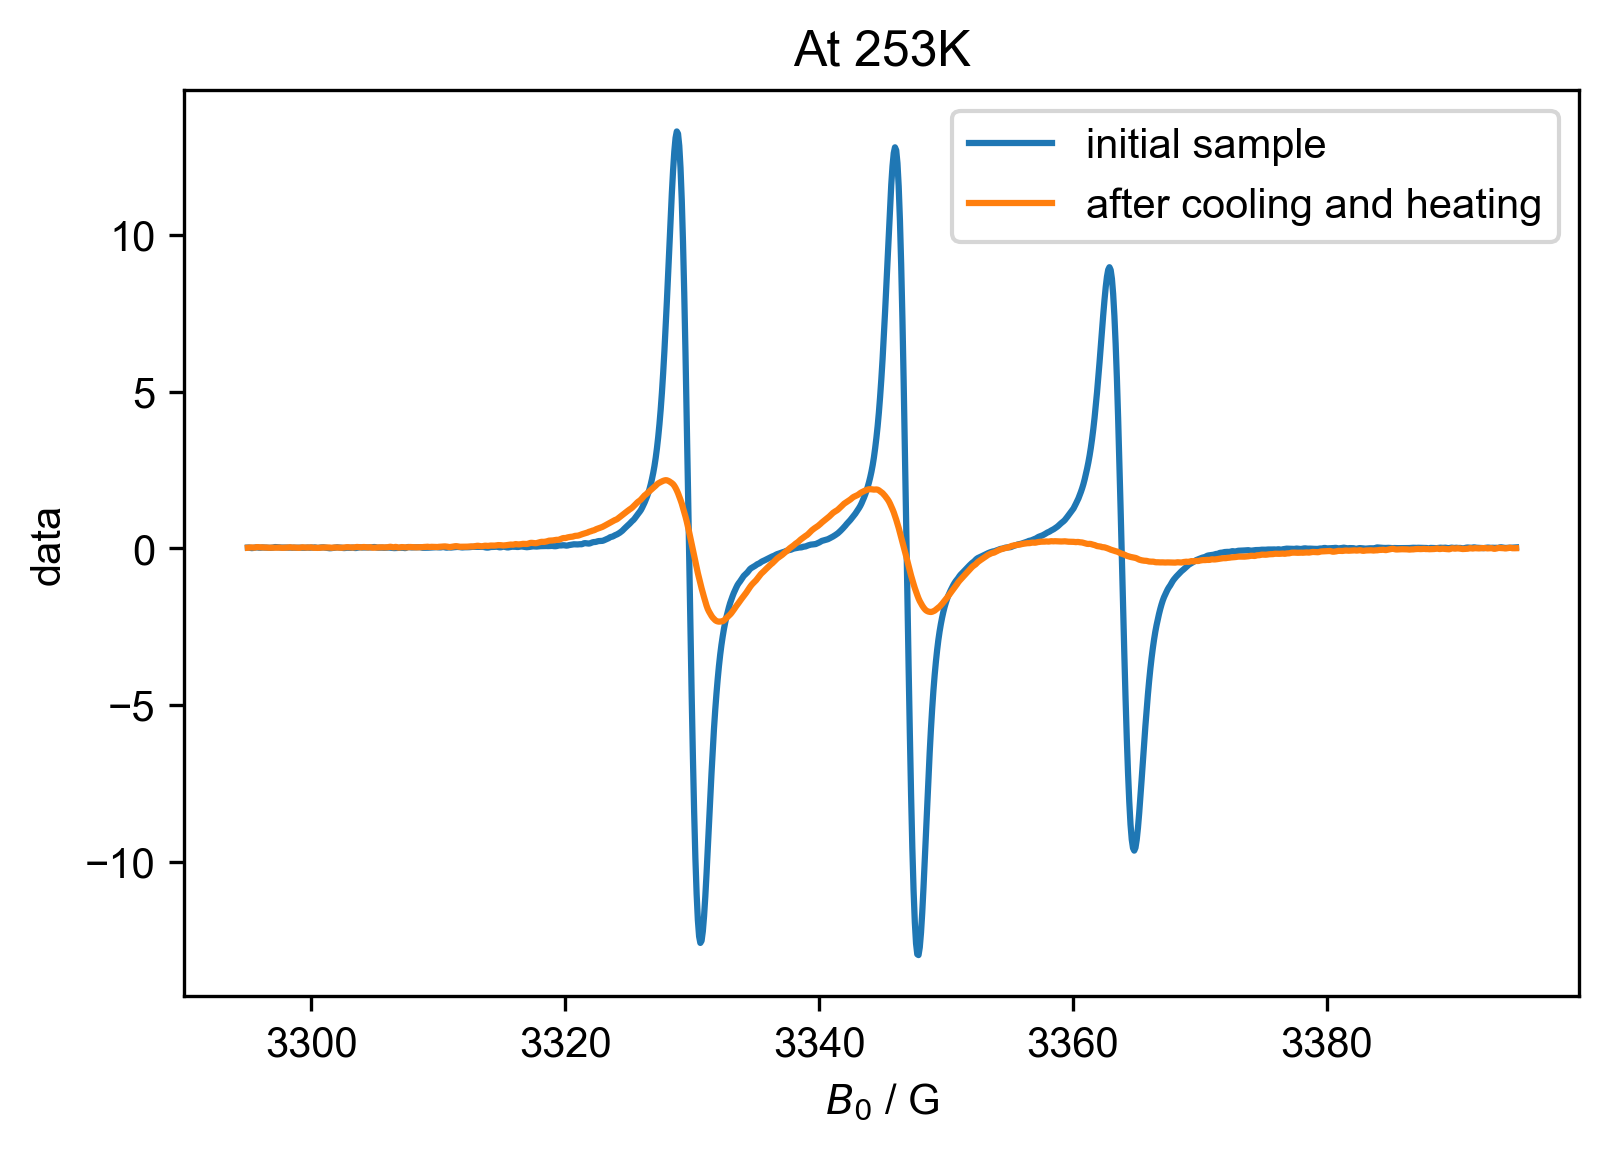

In [14]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="initial sample")
plot(d2["Temperature":253], label="after cooling and heating")
title("At 253K")
legend()

[223.059 224.852 226.86  228.9   230.846 232.866 235.013 237.095 238.908
 241.08  242.405 244.991 246.426 248.511 251.093 253.002 255.129 257.303
 259.351 261.131 263.246 265.327 267.322 269.271 271.35  273.287 274.672
 276.577 279.079 281.212 283.   ]
[222.974 225.4   227.    229.206 231.096 233.128 235.192 236.958 239.085
 241.039 243.134 244.977 247.429 249.484 251.557 253.478 255.603 257.328
 258.825 260.672 263.401 265.404 267.27  269.244 270.722 272.74  275.357
 276.754 279.37  281.338 282.821]


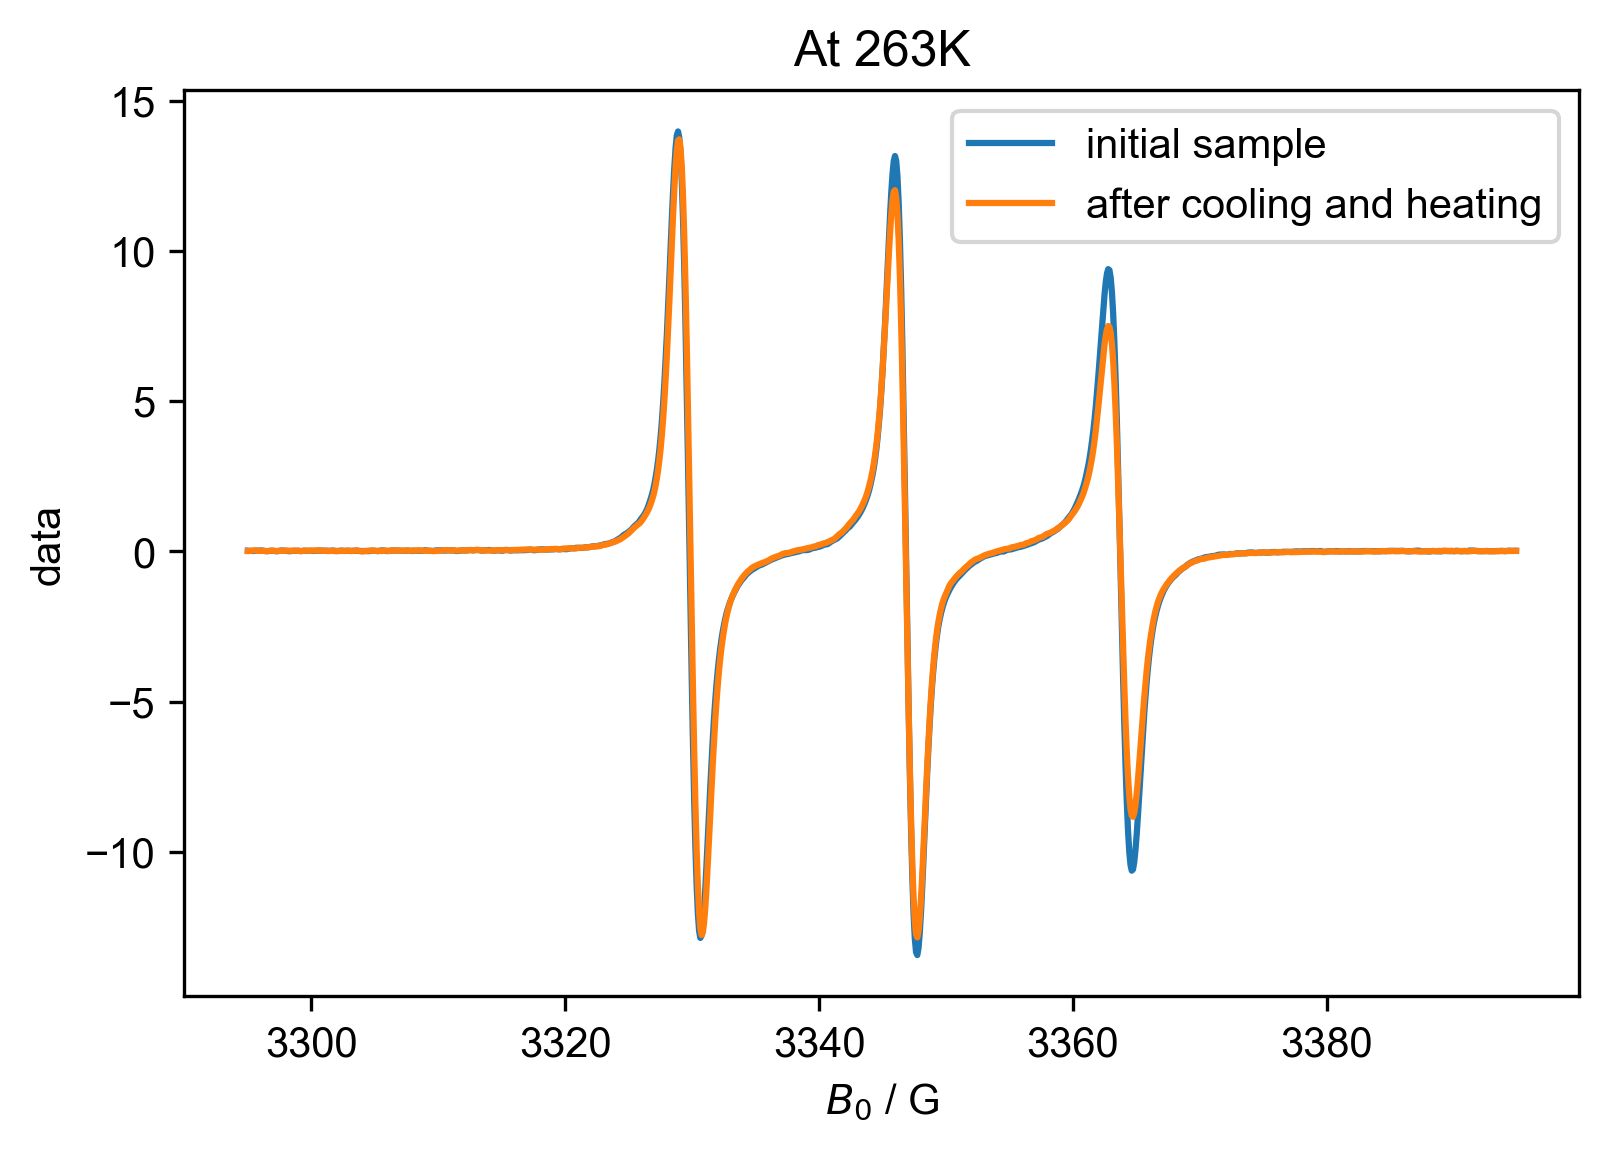

In [15]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="initial sample")
plot(d2["Temperature":263], label="after cooling and heating")
title("At 263K")
legend()

[223.059 224.852 226.86  228.9   230.846 232.866 235.013 237.095 238.908
 241.08  242.405 244.991 246.426 248.511 251.093 253.002 255.129 257.303
 259.351 261.131 263.246 265.327 267.322 269.271 271.35  273.287 274.672
 276.577 279.079 281.212 283.   ]
[222.974 225.4   227.    229.206 231.096 233.128 235.192 236.958 239.085
 241.039 243.134 244.977 247.429 249.484 251.557 253.478 255.603 257.328
 258.825 260.672 263.401 265.404 267.27  269.244 270.722 272.74  275.357
 276.754 279.37  281.338 282.821]


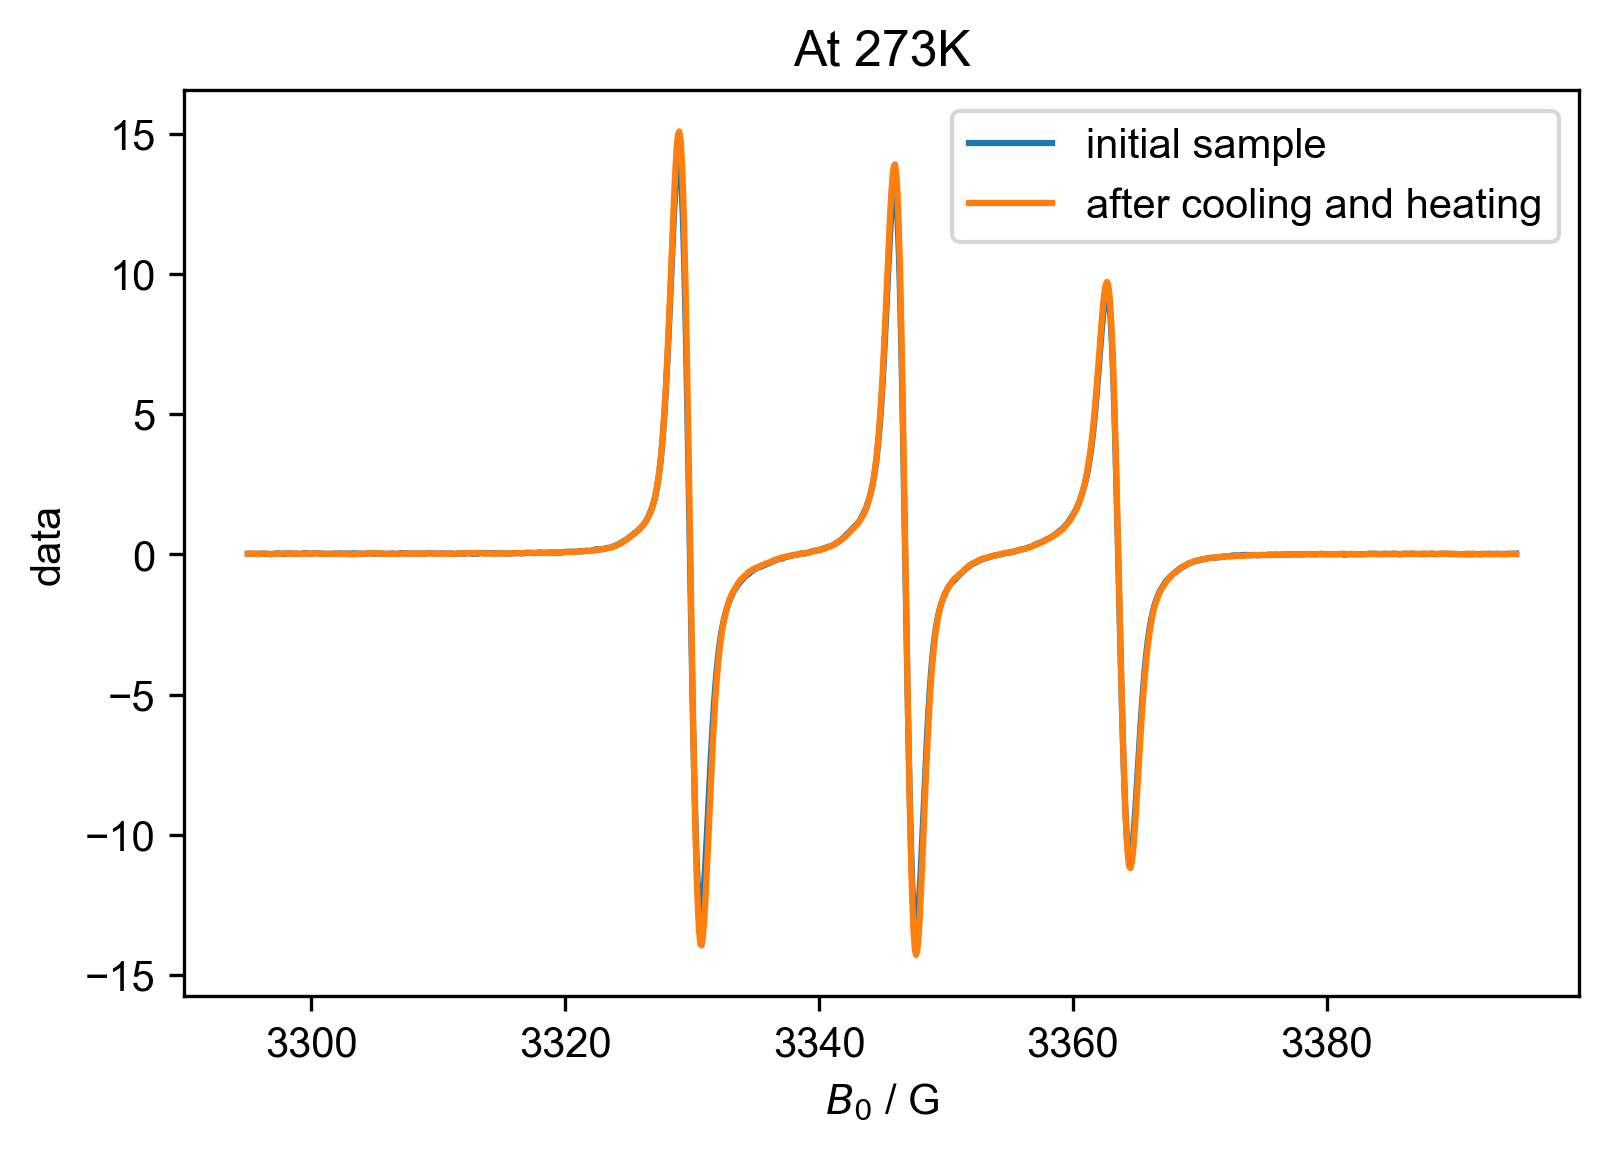

In [16]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":273], label="initial sample")
plot(d2["Temperature":273], label="after cooling and heating")
title("At 273K")
legend()

[223.059 224.852 226.86  228.9   230.846 232.866 235.013 237.095 238.908
 241.08  242.405 244.991 246.426 248.511 251.093 253.002 255.129 257.303
 259.351 261.131 263.246 265.327 267.322 269.271 271.35  273.287 274.672
 276.577 279.079 281.212 283.   ]
[222.974 225.4   227.    229.206 231.096 233.128 235.192 236.958 239.085
 241.039 243.134 244.977 247.429 249.484 251.557 253.478 255.603 257.328
 258.825 260.672 263.401 265.404 267.27  269.244 270.722 272.74  275.357
 276.754 279.37  281.338 282.821]


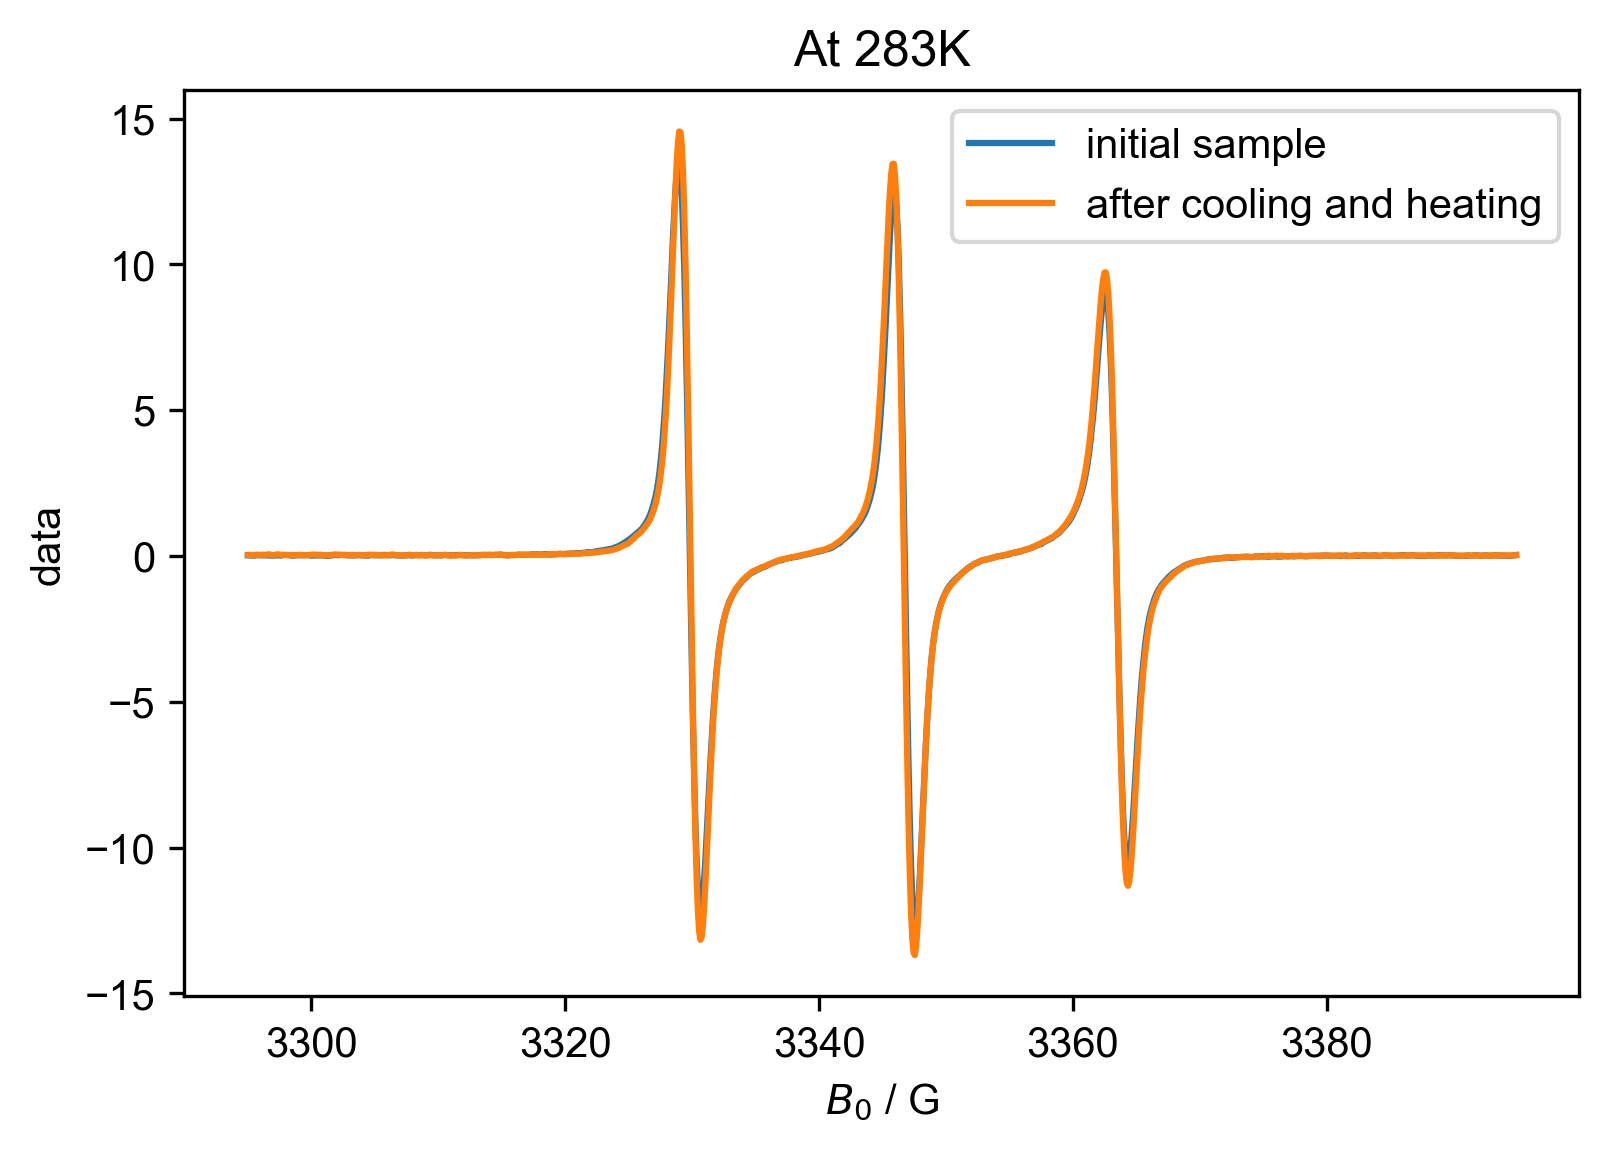

In [17]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("At 283K")
legend()

In [18]:
# #Normalized
# figure(dpi=300, figsize=(7,4))
# plot(d1["Temperature": 283] / d1["Temperature": 283].max(), label= "initial sample")
# plot(d2["Temperature": 283] / d2["Temperature": 283].max(), label= "after cooling and heating")
# title("Normalized TEMPO-SO$_4$ w$_0= 20$ in Dodecane near room temperature (283K)")
# legend()

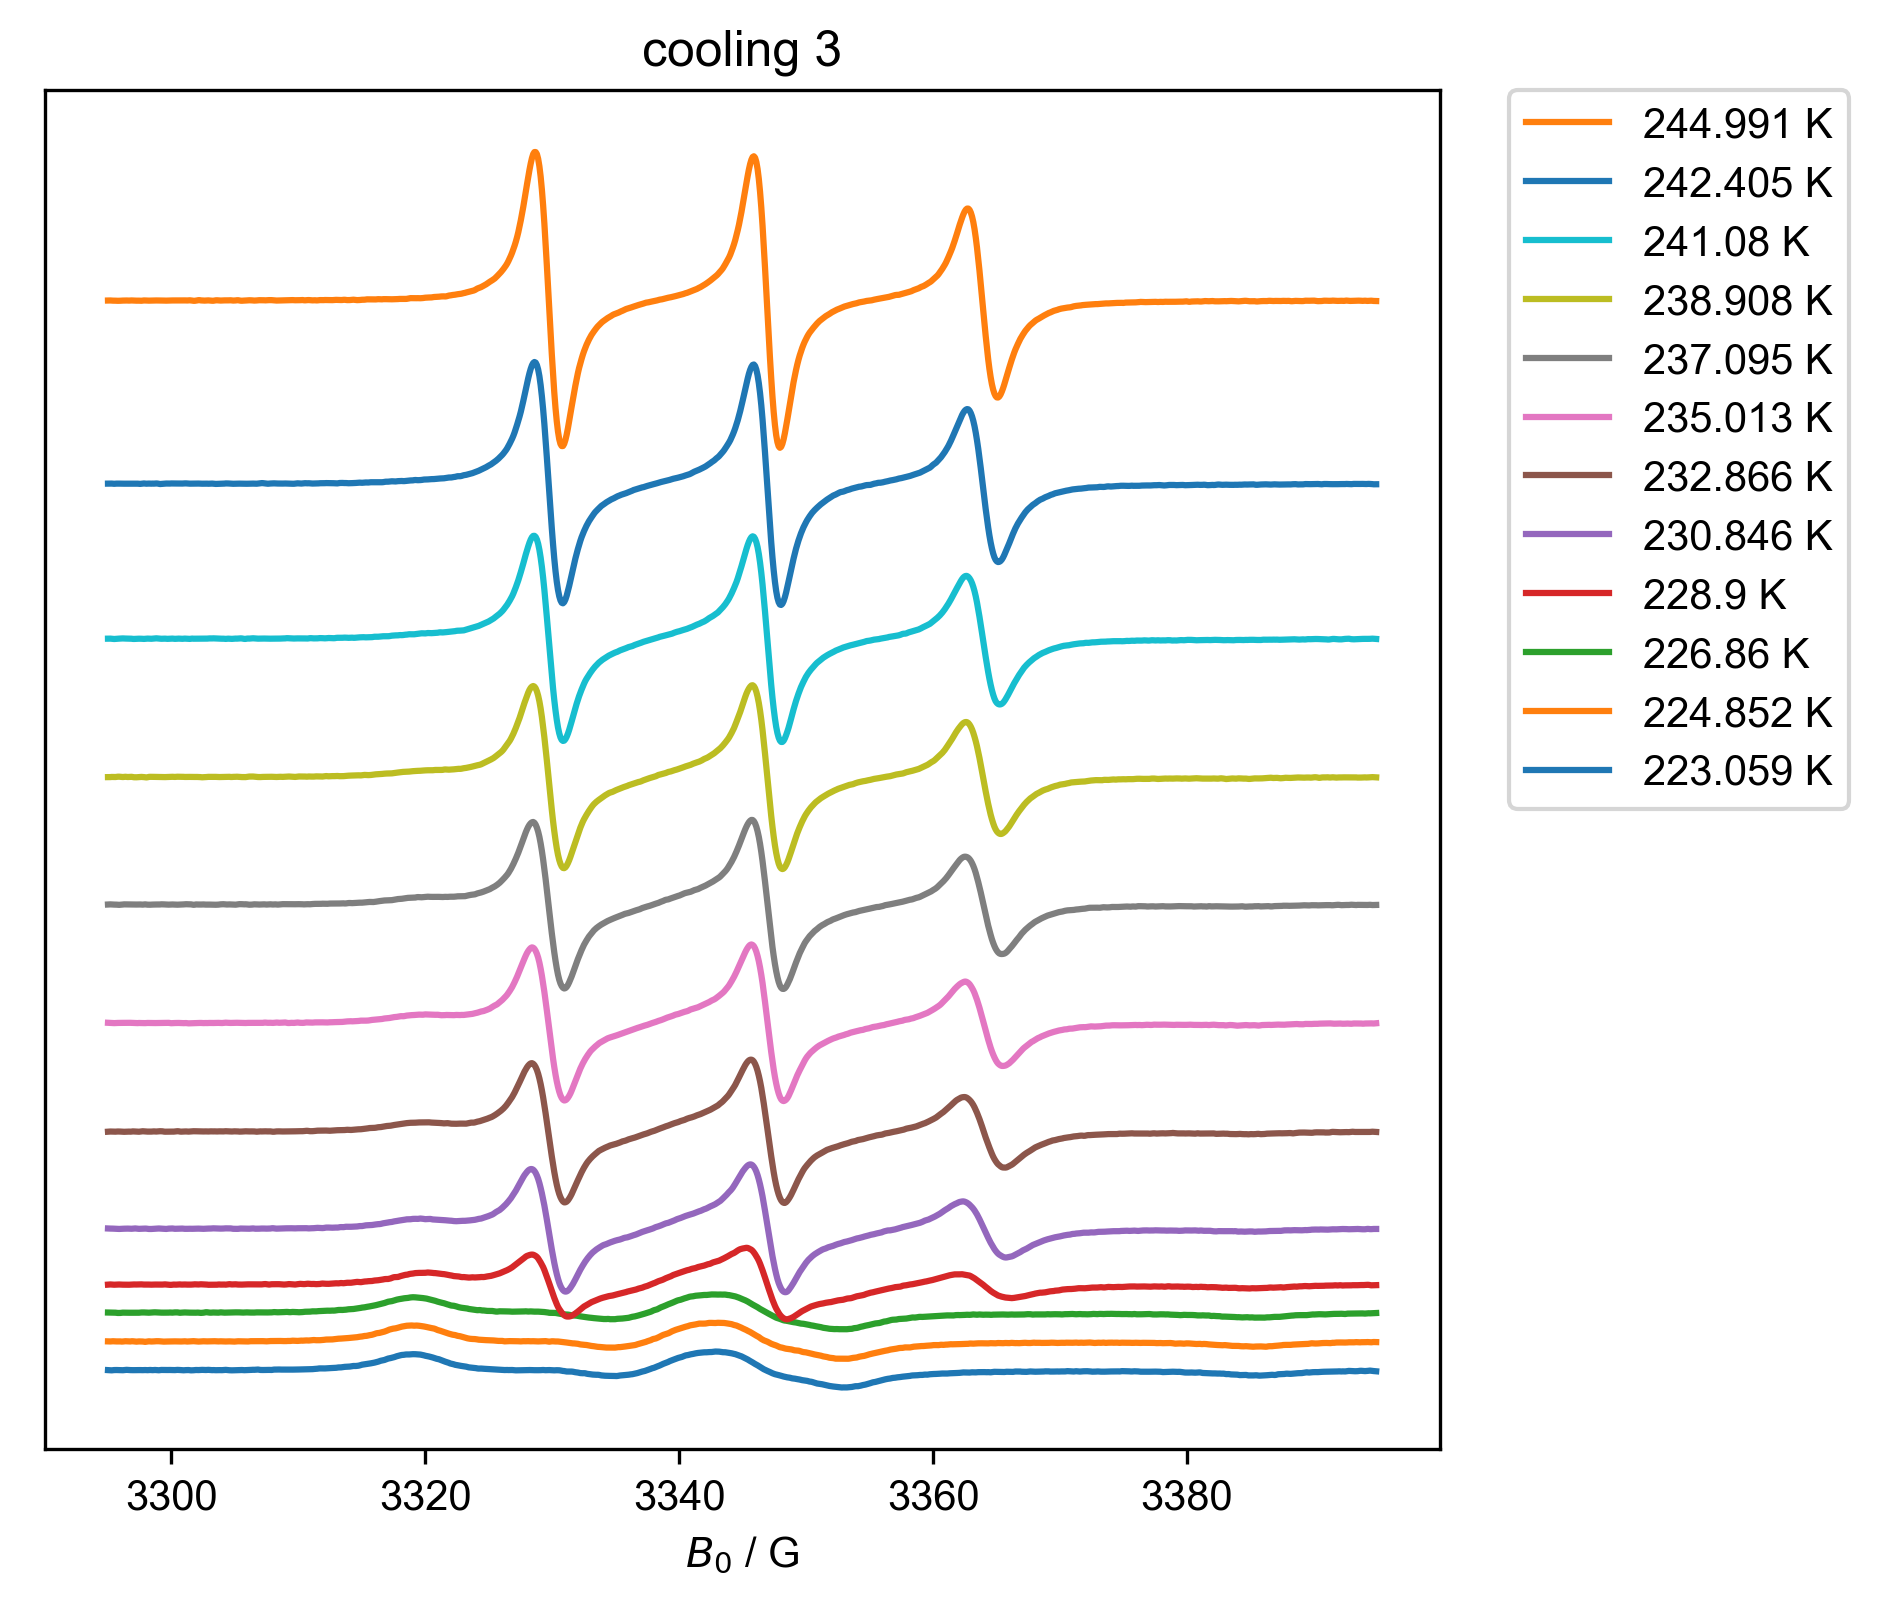

In [33]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("cooling 3", (200, 245))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

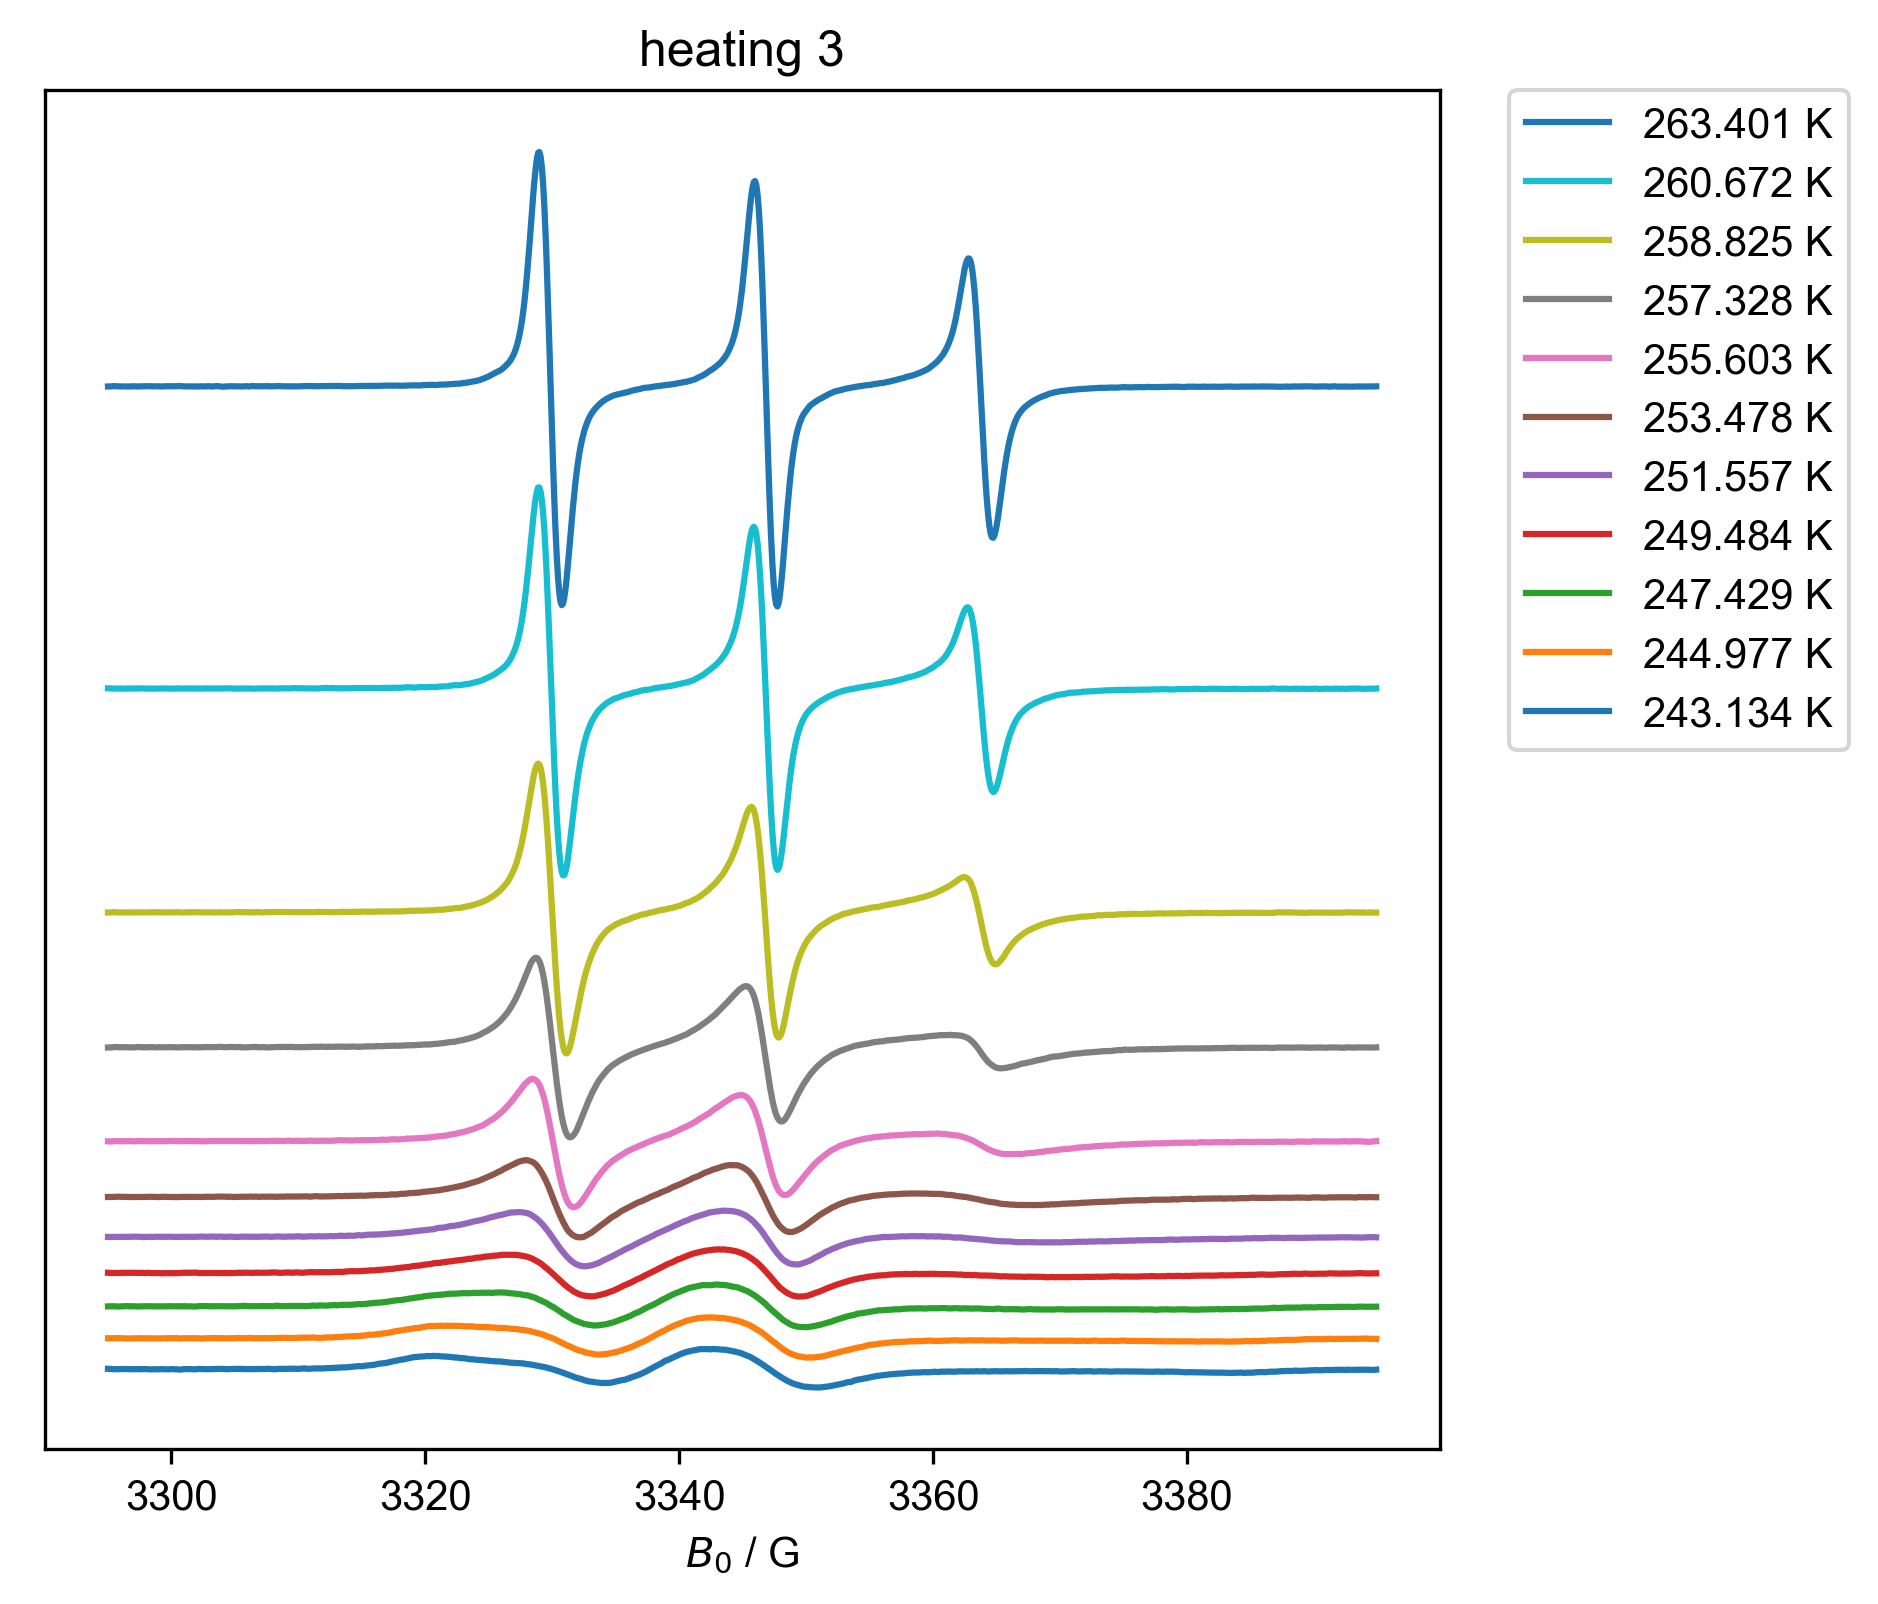

In [35]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("heating 3", (243, 265)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()